# Práctica 9. Estados de varios qubits, entrelazamiento y Bell

**Asignatura:** Computación cuántica  
**Sesión:** 9     
**Entorno recomendado:** Jupyter Notebook

En esta práctica se trabajará con sistemas de dos qubits, producto tensorial, puerta CNOT, estados de Bell, correlaciones cuánticas y una primera aproximación a la desigualdad CHSH.

## Objetivos

Al finalizar la práctica deberás ser capaz de:

- Representar estados de dos qubits mediante vectores complejos.
- Construir estados compuestos usando producto tensorial.
- Calcular probabilidades de medida para sistemas de dos qubits.
- Implementar circuitos de dos qubits en Qiskit.
- Aplicar e interpretar la puerta CNOT.
- Construir los cuatro estados de Bell.
- Medir estados entrelazados con distintos números de shots.
- Analizar correlaciones cuánticas.
- Distinguir un estado entrelazado de una mezcla clásica.
- Interpretar de forma básica el significado de CHSH.


## 1. Preparación del entorno

Ejecuta esta celda antes de comenzar. Si alguna importación falla, revisa que el entorno tenga instalados `qiskit` y `qiskit-aer`.


In [1]:
# %pip install qiskit qiskit-aer matplotlib pylatexenc sympy

import matplotlib.pyplot as plt
import numpy as np

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

def applyStyle():
    plt.style.use("default")

    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif", "serif"]
    plt.rcParams["font.size"] = 12
    plt.rcParams["axes.labelsize"] = 12
    plt.rcParams["axes.titlesize"] = 12
    plt.rcParams["xtick.labelsize"] = 10
    plt.rcParams["ytick.labelsize"] = 10
    plt.rcParams["legend.fontsize"] = 10

    plt.rcParams["xtick.direction"] = "in"
    plt.rcParams["ytick.direction"] = "in"
    plt.rcParams["xtick.top"] = True
    plt.rcParams["ytick.right"] = True
    plt.rcParams["xtick.minor.visible"] = True
    plt.rcParams["ytick.minor.visible"] = True

    plt.rcParams["lines.linewidth"] = 1.0
    plt.rcParams["lines.markersize"] = 3

    plt.rcParams["legend.frameon"] = True
    plt.rcParams["legend.edgecolor"] = "black"
    plt.rcParams["legend.fancybox"] = False

COLOR_TARGET = "#5d54a4"
COLOR_PRED = "#9154a4"
COLOR_ERR = "#404040"

SEED = 42
np.set_printoptions(precision=5, suppress=True)

applyStyle()


def probsDict(state, decimals=5):
    return {str(k): round(float(v), decimals) for k, v in state.probabilities_dict().items()}

## 2. Parte A. Estados de dos qubits con NumPy

### Ejercicio 1. Base computacional de dos qubits

Define con NumPy los estados:

$$
|0\rangle,\quad |1\rangle
$$

y construye mediante `np.kron`:

$$
|00\rangle,\quad |01\rangle,\quad |10\rangle,\quad |11\rangle
$$

Muestra cada vector y comprueba su dimensión.


In [ ]:
ket0 = np.array([1, 0], dtype=complex)
ket1 = np.array([0, 1], dtype=complex)

ket00 = np.kron(ket0, ket0)
ket01 = np.kron(ket0, ket1)
ket10 = np.kron(ket1, ket0)
ket11 = np.kron(ket1, ket1)

basisStates = {
    "|00>": ket00,
    "|01>": ket01,
    "|10>": ket10,
    "|11>": ket11,
}

for name, state in basisStates.items():
    print(f"{name} = {state}")
    print(f"shape = {state.shape}")
    print(f"index = {int(np.argmax(np.abs(state)))}")
    print()

ketSum = ket0 + ket1
print(f"|0> + |1>  = {ketSum}")
print(f"shape = {ketSum.shape}")
print(f"norm  = {np.linalg.norm(ketSum):.5f}")

|00> = [1.+0.j 0.+0.j 0.+0.j 0.+0.j]
  shape = (4,)
  index = 0

|01> = [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
  shape = (4,)
  index = 1

|10> = [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
  shape = (4,)
  index = 2

|11> = [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
  shape = (4,)
  index = 3

|0> + |1>  = [1.+0.j 1.+0.j]
  shape = (2,)
  norm  = 1.41421


**Responde:**

1. ¿Cuántas componentes tiene cada vector de dos qubits?
2. ¿Qué representa cada componente?
3. ¿Por qué usamos el producto tensorial y no una suma ordinaria?

**Respuesta:**

1. Cuatro, una por cada combinación de dos bits (2² = 4).

2. La amplitud de cada estado de la base, en el orden 00, 01, 10 y 11. El índice de la componente es la cadena leída en binario, ej: |10⟩ es la componente 2, y su módulo al cuadrado es la probabilidad de medir esa cadena.

3. Porque el sistema conjunto necesita una amplitud por cada combinación de los dos qubits, y eso es lo que da el producto tensorial (2 × 2 = 4 componentes). La suma |0⟩ + |1⟩ sigue siendo un vector de 2 componentes de un solo qubit, y además no está normalizado (norma √2).

### Ejercicio 2. Estado general de dos qubits

Considera el estado:

$$
|\psi\rangle =
\frac{1}{2}|00\rangle+
\frac{1}{2}|01\rangle+
\frac{1}{2}|10\rangle+
\frac{1}{2}|11\rangle
$$

Represéntalo con NumPy y comprueba su norma.

Después implementa una función que calcule las probabilidades de medir `00`, `01`, `10` y `11`.


In [3]:
def computeProbabilities(state, tolerance=1e-10):
    state = np.asarray(state, dtype=complex)

    if state.shape != (4,):
        raise ValueError("A two-qubit state must have exactly four amplitudes")

    if not np.all(np.isfinite(state)):
        raise ValueError("The state contains non-finite values")

    if not np.isclose(np.linalg.norm(state), 1.0, atol=tolerance):
        raise ValueError("The state is not normalized")

    probs = np.abs(state) ** 2

    return {format(k, "02b"): float(probs[k]) for k in range(4)}


psiUniform = (ket00 + ket01 + ket10 + ket11) / 2
probsUniform = computeProbabilities(psiUniform)

print(f"psi           = {psiUniform}")
print(f"norm          = {np.linalg.norm(psiUniform):.5f}")
print(f"probabilities = {probsUniform}")
print(f"sum           = {sum(probsUniform.values()):.5f}")
print()

rng = np.random.default_rng(SEED)
singleShots = rng.choice(list(probsUniform), size=5, p=list(probsUniform.values()))
print(f"5 single measurements: {[str(s) for s in singleShots]}")
print()

invalidCases = {
    "notNormalized": ([1, 1, 1, 1], "norm 2 != 1"),
    "oneQubit": ([1, 0], "2 amplitudes"),
    "withNan": ([np.nan, 0, 0, 1], "NaN amplitude"),
}

for name, (vector, justification) in invalidCases.items():
    try:
        computeProbabilities(vector)
        outcome = "NOT DETECTED"
    except ValueError:
        outcome = "ValueError"
    print(f"{name:15s} -> {outcome:12s} | {justification}")

psi           = [0.5+0.j 0.5+0.j 0.5+0.j 0.5+0.j]
norm          = 1.00000
probabilities = {'00': 0.25, '01': 0.25, '10': 0.25, '11': 0.25}
sum           = 1.00000

5 single measurements: ['11', '01', '11', '10', '00']

notNormalized   -> ValueError   | norm 2 != 1
oneQubit        -> ValueError   | 2 amplitudes
withNan         -> ValueError   | NaN amplitude


**Responde:**

1. ¿Qué probabilidad tiene cada resultado?
2. ¿Cuánto suma el total de probabilidades?
3. ¿Qué resultado se obtiene en una única medida?

**Respuesta:**

1. 1/4 = 0.25 cada uno, las cuatro amplitudes son 1/2 y |1/2|² = 1/4.

2. 1, el estado está normalizado.

3. Una sola cadena de dos bits, elegida al azar con probabilidad 1/4. No salen las cuatro a la vez, ej: cinco medidas seguidas dan 11, 01, 11, 10 y 00.

### Ejercicio 3. Producto tensorial con superposiciones

Construye los estados:

$$
|+\rangle \otimes |0\rangle
$$

$$
|+\rangle \otimes |+\rangle
$$

donde:

$$
|+\rangle = \frac{|0\rangle+|1\rangle}{\sqrt{2}}
$$

Para cada estado, muestra el vector, calcula la norma, calcula las probabilidades e indica qué resultados pueden aparecer al medir.


In [4]:
ketPlus = (ket0 + ket1) / np.sqrt(2)

plus0 = np.kron(ketPlus, ket0)
plusPlus = np.kron(ketPlus, ketPlus)

for name, state in {"|+>|0>": plus0, "|+>|+>": plusPlus}.items():
    probs = computeProbabilities(state)
    print(name)
    print(f"  vector            = {state}")
    print(f"  norm              = {np.linalg.norm(state):.5f}")
    print(f"  probabilities     = {probs}")
    print(f"  possible outcomes = {[k for k, p in probs.items() if p > 1e-10]}")
    print()

print(f"|+>|+> equal to psi (exercise 2)? {np.allclose(plusPlus, psiUniform)}")

|+>|0>
  vector            = [0.70711+0.j 0.     +0.j 0.70711+0.j 0.     +0.j]
  norm              = 1.00000
  probabilities     = {'00': 0.4999999999999999, '01': 0.0, '10': 0.4999999999999999, '11': 0.0}
  possible outcomes = ['00', '10']

|+>|+>
  vector            = [0.5+0.j 0.5+0.j 0.5+0.j 0.5+0.j]
  norm              = 1.00000
  probabilities     = {'00': 0.2499999999999999, '01': 0.2499999999999999, '10': 0.2499999999999999, '11': 0.2499999999999999}
  possible outcomes = ['00', '01', '10', '11']

|+>|+> equal to psi (exercise 2)? True


**Responde:**

1. ¿Qué resultados pueden aparecer en $|+\rangle \otimes |0\rangle$?
2. ¿Qué resultados pueden aparecer en $|+\rangle \otimes |+\rangle$?
3. ¿Es lo mismo tener una superposición de dos qubits que tener entrelazamiento?

**Respuesta:**

1. 00 y 10, con probabilidad 1/2 cada uno. El qubit de la izquierda está en |+⟩ y el de la derecha siempre en |0⟩, así que el bit de la derecha siempre sale 0.

2. Los cuatro, 00, 01, 10 y 11, con 1/4 cada uno. Es el mismo estado |ψ⟩ del ejercicio 2.

3. No. Los dos estados están en superposición pero son separables, se escriben como producto de un estado de cada qubit y cada qubit se puede describir por separado. Hay entrelazamiento cuando el estado conjunto no se puede escribir así.

## 3. Parte B. Puerta CNOT

### Ejercicio 4. CNOT sobre estados de la base

Crea cuatro circuitos en Qiskit para comprobar la acción de CNOT sobre:

$$
|00\rangle,
|01\rangle,
|10\rangle,
|11\rangle
$$

Usa `Statevector.from_instruction()` para obtener el estado final.

Recuerda que en Qiskit puedes preparar estados de la base aplicando puertas `x()` a los qubits correspondientes.


initial | cx(0, 1) | cx(1, 0)
------------------------------
     00 |       00 |       00
     01 |       11 |       01
     10 |       10 |       11
     11 |       01 |       10



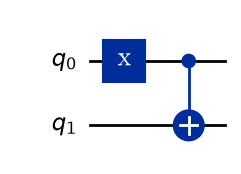

CX·CX|11> = |11>? True

threeBits  -> ValueError   | 3 bits
notBinary  -> ValueError   | not 0 or 1
notString  -> TypeError    | not a string


In [5]:
def prepareBasisState(label):
    if not isinstance(label, str):
        raise TypeError("The label must be a string")

    if len(label) != 2 or any(bit not in "01" for bit in label):
        raise ValueError("The label must be '00', '01', '10' or '11'")

    qc = QuantumCircuit(2)
    for qubit, bit in enumerate(reversed(label)):  # Qiskit labels are q1 q0
        if bit == "1":
            qc.x(qubit)

    return qc


def finalStateCnot(label, control=0, target=1):
    qc = prepareBasisState(label)
    qc.cx(control, target)
    return qc, Statevector.from_instruction(qc)


def basisLabel(state):
    return format(int(np.argmax(np.abs(state.data))), "02b")


print(f"{'initial':>7} | {'cx(0, 1)':>8} | {'cx(1, 0)':>8}")
print("-" * 30)
for label in ["00", "01", "10", "11"]:
    initial = Statevector.from_instruction(prepareBasisState(label))
    qcA, stateA = finalStateCnot(label, control=0, target=1)
    qcB, stateB = finalStateCnot(label, control=1, target=0)
    print(f"{basisLabel(initial):>7} | {basisLabel(stateA):>8} | {basisLabel(stateB):>8}")
print()

qcExample, _ = finalStateCnot("01")
display(qcExample.draw("mpl"))

qcTwice = prepareBasisState("11")
qcTwice.cx(0, 1)
qcTwice.cx(0, 1)
print(f"CX·CX|11> = |11>? {Statevector.from_instruction(qcTwice).equiv(Statevector.from_label('11'))}")
print()

invalidCases = {
    "threeBits": ("011", "3 bits"),
    "notBinary": ("02", "not 0 or 1"),
    "notString": (10, "not a string"),
}

for name, (label, justification) in invalidCases.items():
    try:
        prepareBasisState(label)
        outcome = "NOT DETECTED"
    except (TypeError, ValueError) as error:
        outcome = type(error).__name__
    print(f"{name:10s} -> {outcome:12s} | {justification}")

Completa la tabla:

| Estado inicial | Estado final esperado | Estado obtenido |
|---|---|---|
| $\|00\rangle$ | $\|00\rangle$ | \|00⟩ |
| $\|01\rangle$ | $\|01\rangle$ | \|11⟩ |
| $\|10\rangle$ | $\|11\rangle$ | \|10⟩ |
| $\|11\rangle$ | $\|10\rangle$ | \|01⟩ |

La columna de obtenidos es la de `cx(0, 1)` con las etiquetas de Qiskit, que se leen q1 q0. Las filas de |01⟩ y |10⟩ no coinciden con lo esperado porque la tabla toma como control el bit de la izquierda, y en Qiskit el qubit 0 es el de la derecha. No es un error de la CNOT, con `cx(1, 0)` sale justo la columna esperada.

**Responde:**

1. ¿Qué qubit actúa como control?
2. ¿Qué qubit actúa como objetivo?
3. ¿Cuándo cambia el qubit objetivo?
4. ¿Es reversible la puerta CNOT?

**Respuesta:**

1. El qubit 0 en cx(0, 1), que en las etiquetas de Qiskit es el bit de la derecha.

2. El qubit 1, el bit de la izquierda.

3. Solo cuando el control vale 1, ahí se le aplica una X. Con el control a 0 no cambia nada.

4. Sí. Es su propia inversa, aplicarla dos veces devuelve el estado inicial (CX·CX|11⟩ = |11⟩), y además solo permuta los estados de la base, así que no pierde información.

### Ejercicio 5. CNOT sobre una superposición

Construye el circuito:

```python
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
```

Obtén el vector de estado final y comprueba que corresponde a:

$$
|\Phi^+\rangle =
\frac{|00\rangle+|11\rangle}{\sqrt{2}}
$$


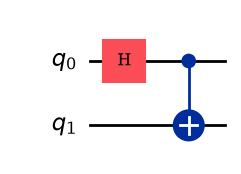

<IPython.core.display.Latex object>

after H       = [0.70711+0.j 0.70711+0.j 0.     +0.j 0.     +0.j]
after CX      = [0.70711+0.j 0.     +0.j 0.     +0.j 0.70711+0.j]
probabilities = {'00': 0.5, '11': 0.5}
equal to (|00> + |11>)/sqrt(2)? True

|+>|0>   -> a00·a11 - a01·a10 = 0.0000 | separable? True
|+>|+>   -> a00·a11 - a01·a10 = 0.0000 | separable? True
after H  -> a00·a11 - a01·a10 = 0.0000 | separable? True
Phi+     -> a00·a11 - a01·a10 = 0.5000 | separable? False


In [6]:
qcPhiPlus = QuantumCircuit(2)
qcPhiPlus.h(0)
qcPhiPlus.cx(0, 1)

qcOnlyH = QuantumCircuit(2)
qcOnlyH.h(0)

statePhiPlus = Statevector.from_instruction(qcPhiPlus)
stateOnlyH = Statevector.from_instruction(qcOnlyH)
phiPlus = (ket00 + ket11) / np.sqrt(2)

display(qcPhiPlus.draw("mpl"))
display(statePhiPlus.draw("latex"))

print(f"after H       = {stateOnlyH.data}")
print(f"after CX      = {statePhiPlus.data}")
print(f"probabilities = {probsDict(statePhiPlus)}")
print(f"equal to (|00> + |11>)/sqrt(2)? {np.allclose(statePhiPlus.data, phiPlus)}")
print()


def isSeparable(state, tolerance=1e-10):
    state = np.asarray(state, dtype=complex)

    if state.shape != (4,):
        raise ValueError("A two-qubit state must have exactly four amplitudes")

    # (a|0> + b|1>) ⊗ (c|0> + d|1>) gives a00·a11 = a01·a10
    return bool(np.isclose(state[0] * state[3] - state[1] * state[2], 0, atol=tolerance))


for name, state in {"|+>|0>": plus0, "|+>|+>": plusPlus, "after H": stateOnlyH.data, "Phi+": statePhiPlus.data}.items():
    det = state[0] * state[3] - state[1] * state[2]
    print(f"{name:8s} -> a00·a11 - a01·a10 = {abs(det):.4f} | separable? {isSeparable(state)}")

**Responde:**

1. ¿Qué estado hay después de aplicar $H$ al primer qubit?
2. ¿Qué efecto tiene CNOT sobre cada rama de la superposición?
3. ¿Por qué el estado final no puede interpretarse como dos qubits independientes?

**Respuesta:**

1. (|00⟩ + |01⟩)/√2, es decir |0⟩ ⊗ |+⟩ en las etiquetas de Qiskit (q1 q0). El qubit 0 está en |+⟩, el qubit 1 sigue en |0⟩ y el estado todavía es separable.

2. Actúa sobre cada rama por separado. En |00⟩ el control vale 0 y no cambia nada, y en |01⟩ el control vale 1 y el objetivo pasa a 1, que da |11⟩. Queda (|00⟩ + |11⟩)/√2.

3. Porque no se puede escribir como producto de un estado de cada qubit. Si fuera (a|0⟩ + b|1⟩) ⊗ (c|0⟩ + d|1⟩), para tener |00⟩ y |11⟩ harían falta ac ≠ 0 y bd ≠ 0, pero entonces también aparecerían |01⟩ y |10⟩. Con las amplitudes, un estado producto cumple α₀₀α₁₁ − α₀₁α₁₀ = 0, y aquí sale 1/2. Ningún qubit tiene un estado propio, solo el par.

## 4. Parte C. Estados de Bell

### Ejercicio 6. Construcción de los cuatro estados de Bell

Construye circuitos para preparar los cuatro estados:

$$
|\Phi^+\rangle =
\frac{|00\rangle+|11\rangle}{\sqrt{2}}
$$

$$
|\Phi^-\rangle =
\frac{|00\rangle-|11\rangle}{\sqrt{2}}
$$

$$
|\Psi^+\rangle =
\frac{|01\rangle+|10\rangle}{\sqrt{2}}
$$

$$
|\Psi^-\rangle =
\frac{|01\rangle-|10\rangle}{\sqrt{2}}
$$

Puedes partir del circuito base `H` + `CX` y añadir puertas `X` o `Z` cuando sea necesario.


Phi+


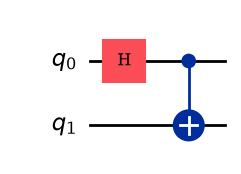

<IPython.core.display.Latex object>

  vector           = [0.70711+0.j 0.     +0.j 0.     +0.j 0.70711+0.j]
  probabilities    = {'00': 0.4999999999999999, '01': 0.0, '10': 0.0, '11': 0.4999999999999999}
  equal to target? True
  separable?       False

Phi-


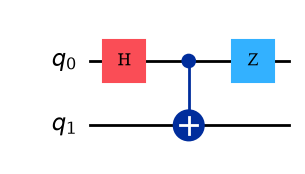

<IPython.core.display.Latex object>

  vector           = [ 0.70711+0.j  0.     +0.j  0.     +0.j -0.70711+0.j]
  probabilities    = {'00': 0.4999999999999999, '01': 0.0, '10': 0.0, '11': 0.4999999999999999}
  equal to target? True
  separable?       False

Psi+


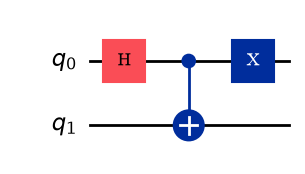

<IPython.core.display.Latex object>

  vector           = [0.     +0.j 0.70711+0.j 0.70711+0.j 0.     +0.j]
  probabilities    = {'00': 0.0, '01': 0.4999999999999999, '10': 0.4999999999999999, '11': 0.0}
  equal to target? True
  separable?       False

Psi-


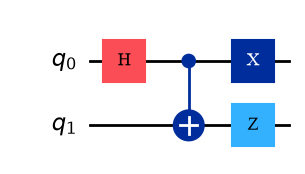

<IPython.core.display.Latex object>

  vector           = [ 0.     +0.j  0.70711+0.j -0.70711+0.j  0.     +0.j]
  probabilities    = {'00': 0.0, '01': 0.4999999999999999, '10': 0.4999999999999999, '11': 0.0}
  equal to target? True
  separable?       False

|<i|j>| between Bell states (Phi+, Phi-, Psi+, Psi-) =
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


In [7]:
def phiPlusCircuit():
    qc = QuantumCircuit(2)
    qc.h(0)
    qc.cx(0, 1)
    return qc


def phiMinusCircuit():
    qc = phiPlusCircuit()
    qc.z(0)
    return qc


def psiPlusCircuit():
    qc = phiPlusCircuit()
    qc.x(0)
    return qc


def psiMinusCircuit():
    qc = phiPlusCircuit()
    qc.x(0)
    qc.z(1)
    return qc


bellCircuits = {
    "Phi+": phiPlusCircuit(),
    "Phi-": phiMinusCircuit(),
    "Psi+": psiPlusCircuit(),
    "Psi-": psiMinusCircuit(),
}

bellTargets = {
    "Phi+": (ket00 + ket11) / np.sqrt(2),
    "Phi-": (ket00 - ket11) / np.sqrt(2),
    "Psi+": (ket01 + ket10) / np.sqrt(2),
    "Psi-": (ket01 - ket10) / np.sqrt(2),
}

bellStates = {}

for name, qc in bellCircuits.items():
    state = Statevector.from_instruction(qc)
    bellStates[name] = state

    print(name)
    display(qc.draw("mpl"))
    display(state.draw("latex"))
    print(f"  vector           = {state.data}")
    print(f"  probabilities    = {computeProbabilities(state.data)}")
    print(f"  equal to target? {np.allclose(state.data, bellTargets[name])}")
    print(f"  separable?       {isSeparable(state.data)}")
    print()

overlaps = np.array([[abs(np.vdot(bellStates[a].data, bellStates[b].data)) for b in bellStates] for a in bellStates])
print("|<i|j>| between Bell states (Phi+, Phi-, Psi+, Psi-) =")
print(overlaps)

Completa:

| Estado de Bell | Amplitudes no nulas | Resultados posibles | Probabilidades |
|---|---|---|---|
| $\|\Phi^+\rangle$ | \|00⟩ y \|11⟩, las dos 1/√2 | 00, 11 | 0.5 y 0.5 |
| $\|\Phi^-\rangle$ | \|00⟩ con 1/√2 y \|11⟩ con −1/√2 | 00, 11 | 0.5 y 0.5 |
| $\|\Psi^+\rangle$ | \|01⟩ y \|10⟩, las dos 1/√2 | 01, 10 | 0.5 y 0.5 |
| $\|\Psi^-\rangle$ | \|01⟩ con 1/√2 y \|10⟩ con −1/√2 | 01, 10 | 0.5 y 0.5 |

Los circuitos parten de H + CX (Φ⁺) y añaden Z en q0 para el signo − (Φ⁻), X en q0 para pasar a 01 y 10 (Ψ⁺), y X en q0 más Z en q1 para Ψ⁻. Los cuatro coinciden con NumPy, ninguno es separable y son ortonormales, la matriz de |⟨i|j⟩| sale la identidad.


### Ejercicio 7. Medida con distintos números de shots

Mide cada estado de Bell con:

```python
shots = [100, 1000, 10000]
```

Para cada caso, guarda los conteos obtenidos.


In [8]:
def runWithMeasurement(qcNoMeasure, shots=1000, seed=SEED):
    if not isinstance(qcNoMeasure, QuantumCircuit):
        raise TypeError("The circuit must be a QuantumCircuit")

    if qcNoMeasure.count_ops().get("measure", 0) > 0:
        raise ValueError("The circuit must not contain measurements")

    if isinstance(shots, bool) or not isinstance(shots, (int, np.integer)):
        raise TypeError("shots must be an integer")

    if shots <= 0:
        raise ValueError("shots must be positive")

    n = qcNoMeasure.num_qubits
    qc = QuantumCircuit(n, n)
    qc.compose(qcNoMeasure, inplace=True)
    qc.measure(range(n), range(n))  # qi -> ci

    simulator = AerSimulator(seed_simulator=seed)
    qcTranspiled = transpile(qc, simulator)
    result = simulator.run(qcTranspiled, shots=shots).result()
    return result.get_counts()


shotsList = [100, 1000, 10000]
bellCounts = {}

for name, qc in bellCircuits.items():
    bellCounts[name] = {}
    for shots in shotsList:
        bellCounts[name][shots] = runWithMeasurement(qc, shots=shots)

outcomes = ["00", "01", "10", "11"]

print(f"{'state':>5} | {'shots':>6} | {'N(00)':>6} {'N(01)':>6} {'N(10)':>6} {'N(11)':>6} | {'max |f - P|':>11} | {'0.5/sqrt(N)':>11}")
print("-" * 76)
for name in bellCircuits:
    probs = computeProbabilities(bellStates[name].data)
    for shots in shotsList:
        counts = bellCounts[name][shots]
        n = [counts.get(k, 0) for k in outcomes]
        maxError = max(abs(counts.get(k, 0) / shots - p) for k, p in probs.items())
        print(f"{name:>5} | {shots:>6} | {n[0]:>6} {n[1]:>6} {n[2]:>6} {n[3]:>6} | {maxError:>11.4f} | {0.5 / np.sqrt(shots):>11.4f}")
print()

print(f"originals without measurements: {all(qc.num_clbits == 0 for qc in bellCircuits.values())}")
print()

measuredBell = QuantumCircuit(2, 2)
measuredBell.compose(phiPlusCircuit(), inplace=True)
measuredBell.measure([0, 1], [0, 1])

invalidCases = {
    "notACircuit": (("not a circuit", 100), "not a QuantumCircuit"),
    "withMeasures": ((measuredBell, 100), "circuit already measured"),
    "zeroShots": ((phiPlusCircuit(), 0), "shots = 0"),
    "boolShots": ((phiPlusCircuit(), True), "bool is not a number of shots"),
}

for name, ((circuit, n), justification) in invalidCases.items():
    try:
        runWithMeasurement(circuit, shots=n)
        outcome = "NOT DETECTED"
    except (TypeError, ValueError) as error:
        outcome = type(error).__name__
    print(f"{name:15s} -> {outcome:12s} | {justification}")

state |  shots |  N(00)  N(01)  N(10)  N(11) | max |f - P| | 0.5/sqrt(N)
----------------------------------------------------------------------------
 Phi+ |    100 |     48      0      0     52 |      0.0200 |      0.0500
 Phi+ |   1000 |    510      0      0    490 |      0.0100 |      0.0158
 Phi+ |  10000 |   4932      0      0   5068 |      0.0068 |      0.0050
 Phi- |    100 |     48      0      0     52 |      0.0200 |      0.0500
 Phi- |   1000 |    510      0      0    490 |      0.0100 |      0.0158
 Phi- |  10000 |   4932      0      0   5068 |      0.0068 |      0.0050
 Psi+ |    100 |      0     52     48      0 |      0.0200 |      0.0500
 Psi+ |   1000 |      0    490    510      0 |      0.0100 |      0.0158
 Psi+ |  10000 |      0   5068   4932      0 |      0.0068 |      0.0050
 Psi- |    100 |      0     52     48      0 |      0.0200 |      0.0500
 Psi- |   1000 |      0    490    510      0 |      0.0100 |      0.0158
 Psi- |  10000 |      0   5068   4932      0 | 

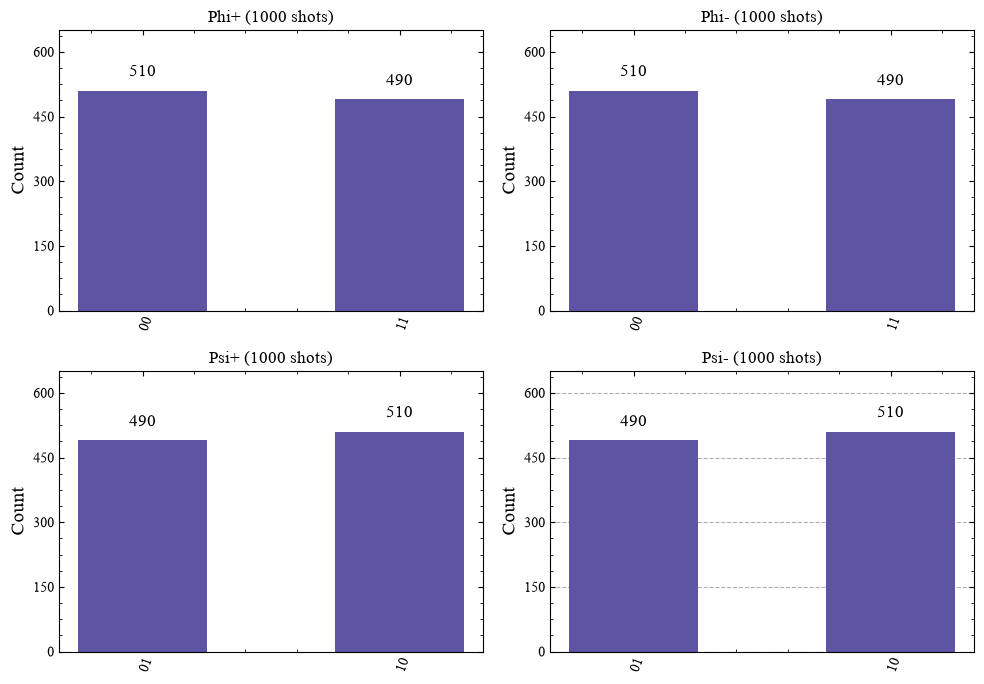

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.flatten()

for ax, name in zip(axes, bellCircuits):
    plot_histogram(bellCounts[name][1000], ax=ax, color=COLOR_TARGET)
    ax.set_title(f"{name} (1000 shots)")
    ax.set_ylim(0, 650)

plt.tight_layout()
plt.show()

**Responde:**

1. ¿Los conteos coinciden exactamente con las probabilidades teóricas?
2. ¿Qué ocurre al aumentar el número de shots?
3. ¿Qué resultados aparecen para $|\Phi^+\rangle$ y $|\Phi^-\rangle$?
4. ¿Qué resultados aparecen para $|\Psi^+\rangle$ y $|\Psi^-\rangle$?
5. ¿Permite esta medida distinguir siempre el signo $+$ del signo $-$?

**Respuesta:**

1. No. Ej: con 1000 shots Φ⁺ da 510 y 490 en vez de 500 y 500. La diferencia máxima con la probabilidad está siempre por debajo de 2σ, con σ = 0.5/√N.

2. Las frecuencias se acercan a 0.5, el error esperado baja como 1/√N (0.05, 0.016 y 0.005). Lo que no cambia es que nunca sale ninguna cadena con probabilidad 0.

3. Solo 00 y 11, en los dos.

4. Solo 01 y 10, en los dos.

5. No. Φ⁺ y Φ⁻ tienen las mismas probabilidades, y con la misma semilla dan hasta los mismos conteos, igual que Ψ⁺ y Ψ⁻. El signo es una fase relativa y en la base computacional no se ve. Para distinguirlos hay que medir en otra base, ej: aplicando H a los dos qubits antes de medir.

## 5. Parte D. Correlaciones

### Ejercicio 8. Análisis de correlaciones

A partir de los conteos de los estados de Bell, calcula:

- Número de veces que los bits son iguales.
- Número de veces que los bits son diferentes.
- Frecuencia de bits iguales.
- Frecuencia de bits diferentes.


In [10]:
def validateCounts(counts):
    if not isinstance(counts, dict):
        raise TypeError("counts must be a dict")

    if len(counts) == 0:
        raise ValueError("counts is empty")

    for outcome, count in counts.items():
        if not isinstance(outcome, str) or len(outcome) != 2 or any(bit not in "01" for bit in outcome):
            raise ValueError(f"Invalid outcome: {outcome!r}")

        if isinstance(count, bool) or not isinstance(count, (int, np.integer)):
            raise TypeError("counts must be integers")

        if count < 0:
            raise ValueError("counts must be non-negative")

    if sum(counts.values()) == 0:
        raise ValueError("The total number of counts is zero")


def analyzeCorrelations(counts):
    validateCounts(counts)

    total = sum(counts.values())
    equal = sum(count for outcome, count in counts.items() if outcome[0] == outcome[1])
    different = total - equal

    return {
        "equal": int(equal),
        "different": int(different),
        "fEqual": equal / total,
        "fDifferent": different / total,
    }


bellCorrelations = {}

print(f"{'state':>5} | {'N equal':>7} {'N diff':>6} | {'f equal':>7} {'f diff':>6}")
print("-" * 38)
for name in bellCircuits:
    corr = analyzeCorrelations(bellCounts[name][1000])
    bellCorrelations[name] = corr
    print(f"{name:>5} | {corr['equal']:>7} {corr['different']:>6} | {corr['fEqual']:>7.3f} {corr['fDifferent']:>6.3f}")
print()

invalidCases = {
    "empty": ({}, "no outcomes"),
    "threeBits": ({"000": 5}, "3-bit outcome"),
    "floatCount": ({"00": 2.5}, "not an integer"),
    "negative": ({"00": -1, "11": 3}, "negative count"),
}

for name, (counts, justification) in invalidCases.items():
    try:
        analyzeCorrelations(counts)
        outcome = "NOT DETECTED"
    except (TypeError, ValueError) as error:
        outcome = type(error).__name__
    print(f"{name:10s} -> {outcome:12s} | {justification}")

state | N equal N diff | f equal f diff
--------------------------------------
 Phi+ |    1000      0 |   1.000  0.000
 Phi- |    1000      0 |   1.000  0.000
 Psi+ |       0   1000 |   0.000  1.000
 Psi- |       0   1000 |   0.000  1.000

empty      -> ValueError   | no outcomes
threeBits  -> ValueError   | 3-bit outcome
floatCount -> TypeError    | not an integer
negative   -> ValueError   | negative count


Completa:

| Estado | Frecuencia bits iguales | Frecuencia bits diferentes | Tipo de correlación |
|---|---:|---:|---|
| $\|\Phi^+\rangle$ | 1.000 | 0.000 | Bits iguales |
| $\|\Phi^-\rangle$ | 1.000 | 0.000 | Bits iguales |
| $\|\Psi^+\rangle$ | 0.000 | 1.000 | Bits opuestos |
| $\|\Psi^-\rangle$ | 0.000 | 1.000 | Bits opuestos |

**Responde:**

1. ¿Qué estados producen bits iguales?
2. ¿Qué estados producen bits diferentes?
3. ¿Cada qubit individual parece aleatorio?
4. ¿Los resultados conjuntos son independientes?

**Respuesta:**

1. Φ⁺ y Φ⁻, en los 1000 shots los dos bits salen iguales.

2. Ψ⁺ y Ψ⁻, en los 1000 shots salen distintos.

3. Sí. Cada qubit da 0 o 1 más o menos la mitad de las veces.

4. No. Si fueran independientes, P(00) sería P(q0 = 0)·P(q1 = 0) ≈ 0.26, y en Φ⁺ sale 0.51. Conociendo un bit se sabe el otro con certeza.

### Ejercicio 9. Cada qubit individual

A partir de los conteos de $|\Phi^+\rangle$, calcula la frecuencia de 0 y 1 para cada qubit por separado.

Ten cuidado con el orden de bits mostrado por Qiskit y explica la convención que estás utilizando.


In [ ]:
def frequenciesPerQubit(counts):
    validateCounts(counts)

    total = sum(counts.values())
    freqs = {}

    for qubit in range(2):
        ones = sum(count for outcome, count in counts.items() if outcome[::-1][qubit] == "1")  # q0 is the rightmost bit
        freqs[f"q{qubit}"] = {"0": (total - ones) / total, "1": ones / total}

    return freqs


phiPlusCounts = bellCounts["Phi+"][1000]
individualFrequencies = frequenciesPerQubit(phiPlusCounts)

print(f"counts = {phiPlusCounts}")
print()
print(f"{'qubit':>5} | {'f(0)':>6} {'f(1)':>6}")
print("-" * 21)
for qubit, f in individualFrequencies.items():
    print(f"{qubit:>5} | {f['0']:>6.3f} {f['1']:>6.3f}")
print()

f00 = phiPlusCounts.get("00", 0) / sum(phiPlusCounts.values())
product = individualFrequencies["q0"]["0"] * individualFrequencies["q1"]["0"]
print(f"f(00)              = {f00:.3f}")
print(f"f(q0=0) · f(q1=0)  = {product:.3f}")
print()

print(f"convention check, X only on q0 -> {frequenciesPerQubit(runWithMeasurement(prepareBasisState('01'), shots=100))}")

counts = {'00': 510, '11': 490}

qubit |   f(0)   f(1)
---------------------
   q0 |  0.510  0.490
   q1 |  0.510  0.490

f(00)              = 0.510
f(q0=0) · f(q1=0)  = 0.260   (what independent qubits would give)

convention check, X only on q0 -> {'q0': {'0': 0.0, '1': 1.0}, 'q1': {'0': 1.0, '1': 0.0}}


Completa:

| Qubit | Frecuencia de 0 | Frecuencia de 1 |
|---|---:|---:|
| Qubit 0 | 0.510 | 0.490 |
| Qubit 1 | 0.510 | 0.490 |

Convención: las cadenas de Qiskit se leen q1 q0, así que el qubit 0 es el bit de la derecha. Lo compruebo con una X solo en q0, que da q0 siempre 1 y q1 siempre 0.

**Responde:**

1. ¿Qué distribución tiene cada qubit individualmente?
2. ¿Qué distribución tiene el sistema conjunto?
3. ¿Cómo puede cada qubit parecer aleatorio y, al mismo tiempo, estar perfectamente correlacionado con el otro?

**Respuesta:**

1. Aleatoria, 50/50 en cada qubit (0.510 y 0.490).

2. Solo 00 y 11, cada uno con probabilidad 1/2. Las cadenas 01 y 10 no salen nunca.

3. Porque la aleatoriedad está en el resultado conjunto, no en cada qubit. El par está en una superposición de 00 y 11, así que al medir sale una de las dos al azar, y por eso cada qubit por separado es 50/50, pero los dos bits siempre coinciden. Ningún qubit tiene un valor propio antes de medir, la correlación es del estado entero.

## 6. Parte E. Entrelazamiento frente a mezcla clásica

### Ejercicio 10. Comparación con una mezcla clásica

Simula una mezcla clásica que produzca:

- $|00\rangle$ el 50 % de las veces.
- $|11\rangle$ el 50 % de las veces.

Compárala con el histograma del estado entrelazado $|\Phi^+\rangle$.


classical mixture: {'00': 503, '11': 497}
entangled Phi+:    {'00': 510, '11': 490}


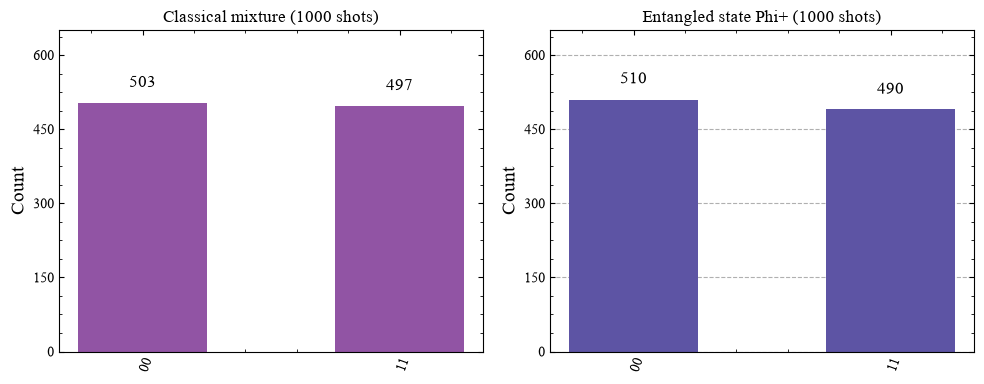

Measuring in the X basis (H on both qubits before measuring):
  entangled Phi+    -> {'00': 510, '11': 490}   f equal = 1.000
  classical mixture -> {'00': 250, '01': 264, '10': 264, '11': 222}   f equal = 0.472


In [12]:
rng = np.random.default_rng(SEED)

results = rng.choice(["00", "11"], size=1000, p=[0.5, 0.5])

values, numbers = np.unique(results, return_counts=True)
mixtureCounts = {str(v): int(n) for v, n in zip(values, numbers)}
entangledCounts = bellCounts["Phi+"][1000]

print(f"classical mixture: {mixtureCounts}")
print(f"entangled Phi+:    {entangledCounts}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_histogram(mixtureCounts, ax=axes[0], color=COLOR_PRED)
plot_histogram(entangledCounts, ax=axes[1], color=COLOR_TARGET)
axes[0].set_title("Classical mixture (1000 shots)")
axes[1].set_title("Entangled state Phi+ (1000 shots)")
for ax in axes:
    ax.set_ylim(0, 650)
plt.tight_layout()
plt.show()

qcPhiPlusX = phiPlusCircuit()
qcPhiPlusX.h([0, 1])

qc00X = prepareBasisState("00")
qc00X.h([0, 1])
qc11X = prepareBasisState("11")
qc11X.h([0, 1])

entangledX = runWithMeasurement(qcPhiPlusX, shots=1000)
counts00X = runWithMeasurement(qc00X, shots=int(mixtureCounts["00"]))
counts11X = runWithMeasurement(qc11X, shots=int(mixtureCounts["11"]))
mixtureX = {k: counts00X.get(k, 0) + counts11X.get(k, 0) for k in outcomes}

print("Measuring in the X basis (H on both qubits before measuring):")
print(f"  entangled Phi+    -> {entangledX}   f equal = {analyzeCorrelations(entangledX)['fEqual']:.3f}")
print(f"  classical mixture -> {mixtureX}   f equal = {analyzeCorrelations(mixtureX)['fEqual']:.3f}")

**Responde:**

1. ¿Son iguales o parecidos los histogramas en la base computacional?
2. ¿Significa eso que la mezcla clásica y el estado entrelazado son lo mismo?
3. ¿Qué información no se observa al medir solo en la base computacional?
4. ¿Qué papel tiene la fase relativa en el estado entrelazado?

**Respuesta:**

1. Prácticamente iguales, solo 00 y 11 con unos 500 de cada (503/497 la mezcla y 510/490 Φ⁺).

2. No. Coinciden en la base computacional, pero en la base X (H en los dos qubits antes de medir) Φ⁺ sigue dando solo 00 y 11, con bits iguales el 100 % de las veces, mientras que la mezcla da las cuatro cadenas y bits iguales solo el 47 %.

3. La fase relativa entre las ramas |00⟩ y |11⟩, es decir, la coherencia. La base Z solo ve los módulos al cuadrado.

4. Es la que hace que las ramas interfieran al cambiar de base. Con el signo + de Φ⁺ las contribuciones a 01 y 10 se cancelan también en la base X, y la correlación se mantiene. En la mezcla no hay amplitudes que interfieran, cada shot es |00⟩ o |11⟩ y la H los deja en superposición uniforme.

### Ejercicio 14. Preguntas finales

Responde de forma razonada:

1. ¿Por qué no toda superposición es entrelazamiento?
2. ¿Por qué $|+\rangle \otimes |+\rangle$ es separable?
3. ¿Por qué $\frac{|00\rangle+|11\rangle}{\sqrt{2}}$ es entrelazado?
4. ¿Por qué una mezcla clásica puede producir el mismo histograma que un estado entrelazado?
5. ¿Por qué hace falta medir en otras bases para distinguir ciertos estados?
6. ¿Por qué el entrelazamiento no permite comunicación instantánea?

**Respuesta:**

1. Porque una superposición puede ser de cada qubit por separado. Si el estado se puede escribir como producto de un estado de cada qubit es separable, aunque tenga varias ramas, ej: |+⟩ ⊗ |0⟩.

2. Porque está escrito como producto de |+⟩ en cada qubit. Las cuatro amplitudes son 1/2 y cumplen α₀₀α₁₁ − α₀₁α₁₀ = 0, así que cada qubit tiene su propio estado y medir uno no cambia el otro.

3. Porque no se puede factorizar, para tener |00⟩ y |11⟩ sin |01⟩ ni |10⟩ no hay ningún producto que funcione (α₀₀α₁₁ − α₀₁α₁₀ = 1/2 ≠ 0). Solo el par tiene un estado definido.

4. Porque en la base computacional solo se ven las probabilidades, y las dos dan 00 y 11 al 50 %. La diferencia está en la fase relativa, que esta medida no ve.

5. Porque estados con las mismas probabilidades en una base pueden diferir en la fase, como Φ⁺ y Φ⁻ o Φ⁺ y la mezcla. Al cambiar de base las ramas interfieren y esas diferencias pasan a ser diferencias de probabilidad.

6. Porque cada persona que mide su qubit obtiene 0 o 1 al azar y no puede elegir el resultado, así que no puede codificar ningún mensaje. La correlación solo aparece cuando se comparan los resultados, y para eso hace falta un canal clásico.